# 04 Adversarial robustness of the semantic receiver (v3: packet-level network, resumable)
Run **after** notebooks 01 and 02. Needs `src/attack_v2.py` (the new one with `attack_e2e`) in your Drive `src` folder. Notebook 03 is not required, but the network model here is the **same packet simulator** as in 03 (code copied in section B2).

**What changed from the previous 04**
* Parts B and C now use the packet simulator of notebook 03 (send order, FEC / ARQ protection, bottleneck queue, bursty loss). Before, the network deleted the lowest-priority blocks by itself, which a real channel cannot do.
* **Resumable**: every finished attack / condition is saved in `results/adv4_cache.json` (and the e2e images in `results/adv4_e2e_*.npy`). If Colab disconnects, run the notebook again from the top; finished items are skipped.
* Leakage is measured on the **whole test set**; the attacks use a fixed random subset (`N_PIXEL`, `N_TAG`).
* Part A no longer loses its results table when later cells reuse a variable name.

## Threat model
| Attacker | Position | Knowledge | Capability | Where |
|---|---|---|---|---|
| **A1 pixel, white-box** | in transit / compromised relay | full receiver | L∞ perturbation ε ≤ 8/255, 8-bit | Part A `clf`, `loc` |
| **A2 pixel, end-to-end** | same | full receiver incl. localizer → crop → classifier | 2-stage PGD: move the crop, then attack the new crop | Part A `e2e` |
| **A3 pixel, transfer** | same | surrogate only (single localizer seed) | craft on surrogate, test on the real receiver | Part A `transfer` |
| **A4 adaptive** | same | full receiver **and** its blur defence | gradient through the differentiable blur | Part A `adaptive_*` |
| **A5 tag attacker** | reads / modifies priority tags | tags only (no pixels) | erase top-tagged blocks, invert or forge tags | Part B |
| **A6 combined** | pixel attack + lossy network | full | e2e PGD, then bursty loss / congestion, uniform vs priority | Part C |

**Assumption for tags (Part B):** the network (sender pacing order and the protection budget) acts on the *public* priority tags. A tampered or decoy tag therefore changes what gets protected. Encrypted / authenticated tags: the attacker cannot read them (blind) and cannot forge them.

**Metrics:** robust AUC (patient-level bootstrap 95 % CI), ASR (correct → wrong among clean-correct images), MMR (malignant predicted benign), localization hit rate, lesion-block delivery, PSNR / SSIM of the perturbation.

In [12]:
from google.colab import drive; drive.mount("/content/drive")
import glob, os, sys, json, time
hits = glob.glob("/content/drive/MyDrive/mammo_semcom/**/src/config.py", recursive=True)
CODE_DIR = os.path.dirname(os.path.dirname(hits[0])); WORK_DIR = "/content/drive/MyDrive/mammo_semcom_work"
sys.path.insert(0, CODE_DIR); print("code:", CODE_DIR)
import numpy as np, pandas as pd, cv2, torch, matplotlib.pyplot as plt
from collections import deque
from src.config import Cfg
from src import data
from src.train import to01, DEVICE
from src.metrics import auc_safe
from src.channel import apply_loss
from src.pipeline import diagnose_all
from src.train_v2 import load_classifier_v2, load_localizer_v2, ReceiverV2
from src.tx_v2 import importance_sets
sys.modules.pop("src.attack_v2", None)                       # make sure the new attack_v2.py is the one in use
from src.attack_v2 import attack, attack_e2e, blur_t, perturb_quality, public_tags, tag_attack

DRY = False                                       # True = quick test of the whole notebook (tiny sizes, separate cache)
N_PIXEL, N_TAG, BS, STEPS = (16, 16, 4, 3) if DRY else (120, 100, 4, 10)      # lower BS if the GPU runs out of memory
EPS = (1, 2, 4, 8)                                 # in 1/255 units
K_TAG, N_BOOT, N_LEAK = (4, 16), 200, (24 if DRY else 0)                      # N_LEAK = 0 -> whole test set
M_SEEDS, RHO, BURST_LEN, RESUME = 3, 0.20, 8.0, True                          # same values as notebooks 01 / 03
SIG = f"{N_PIXEL}_{N_TAG}_{STEPS}" + ("_dry" if DRY else "")

cfg = Cfg(work_dir=WORK_DIR).ensure()
images, masks, images_df, abn_df = data.load_cache(cfg)
heat = np.load(cfg.path("cache", "heatmaps_v2.npy"), mmap_mode="r")
lm = json.load(open(cfg.path("models", "loc_v2.json")))
localizers = [load_localizer_v2(cfg, f"v2_s{s}", lm["act"]) for s in range(M_SEEDS)]
clf, cmeta = load_classifier_v2(cfg); THR = cmeta["thr"]
for mod in (*localizers, clf):
    for p in mod.parameters(): p.requires_grad_(False)
receiver = ReceiverV2(cfg, localizers, clf, sigma=lm["sigma"])

# resumable results store
CK = cfg.path("results", "adv4_cache.json"); CACHE = json.load(open(CK)) if (RESUME and os.path.exists(CK)) else {}
def jf(d): return {k: (float(v) if isinstance(v, (np.floating, np.integer)) else v) for k, v in d.items()}
def cached(key, fn):
    key = f"{SIG}|{key}"
    if key in CACHE: return CACHE[key]
    v = fn(); CACHE[key] = v; json.dump(CACHE, open(CK, "w")); return v
print("finished items found in cache:", sum(k.startswith(SIG) for k in CACHE))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
code: /content/drive/MyDrive/mammo_semcom
finished items found in cache: 0


In [13]:
# ---- data: test images (patient-level split, mixed-label images excluded); fixed random subset for the attacks
te_all = images_df[(images_df.split == "test") & (~images_df.mixed)]
pidc = next((c for c in ("patient_id", "pid") if c in te_all.columns), None)
te = te_all.sample(n=min(max(N_PIXEL, N_TAG), len(te_all)), random_state=cfg.seed).sort_index()
ids = te.img_idx.values; y = te.label.values.astype(int); N = len(ids)
pid = pd.factorize(te[pidc])[0] if pidc else np.arange(N)
img01 = np.stack([to01(images[i]) for i in ids]); M = masks[ids] > 0
H = np.stack([np.asarray(heat[i], np.float32) for i in ids]); BLK = cfg.block
_k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (49, 49)); gt_dil = [cv2.dilate(m.astype(np.uint8), _k) > 0 for m in M]
T = lambda a: torch.from_numpy(np.ascontiguousarray(a)).float()[:, None].to(DEVICE)
denoise = lambda a: np.stack([cv2.GaussianBlur(x, (0, 0), 1.0) for x in a])      # receiver defence = blur_t(sigma=1)

def ev(imgs, defence=False):
    """per-image receiver outputs for a set of (possibly attacked / damaged) images"""
    r = diagnose_all(receiver, denoise(imgs) if defence else imgs)
    hit = np.array([gt_dil[i][int(round(r["cy"][i])), int(round(r["cx"][i]))] for i in range(len(imgs))])
    return dict(p=r["p"], hit=hit)

def boot(fn, idx, n=N_BOOT, seed=0):
    """patient-level bootstrap 95 % CI of fn(index array)"""
    rng = np.random.default_rng(seed); up = np.unique(pid[idx]); g = {u: idx[pid[idx] == u] for u in up}; v = []
    for _ in range(n):
        s = np.concatenate([g[u] for u in rng.choice(up, len(up))]); v.append(fn(s))
    return np.nanpercentile(v, [2.5, 97.5])

ALL = np.arange(N); clean = ev(img01); clean_ok = (clean["p"] >= THR) == y
def summ(r, idx=ALL):
    pr = r["p"] >= THR; ok = clean_ok[idx]
    auc = auc_safe(y[idx], r["p"][idx]); lo, hi = boot(lambda s: auc_safe(y[s], r["p"][s]), idx)
    return jf(dict(AUC=auc, AUC_lo=lo, AUC_hi=hi, ACC=float((pr[idx] == y[idx]).mean()),
                   ASR=float((pr[idx][ok] != y[idx][ok]).mean()) if ok.any() else np.nan,
                   MMR=float((~pr[idx][y[idx] == 1]).mean()), loc_hit=float(r["hit"][idx].mean())))
print(f"images: {N} (malignant {y.sum()}), patients: {len(np.unique(pid))}"); print("clean:", {k: round(v, 3) for k, v in summ(clean).items()})

images: 120 (malignant 47), patients: 102
clean: {'AUC': 0.695, 'AUC_lo': 0.606, 'AUC_hi': 0.797, 'ACC': 0.575, 'ASR': 0.0, 'MMR': 0.34, 'loc_hit': 0.492}


## Part A. Pixel attacks (PGD, L∞, 8-bit)
`clf` attacks the classifier at the clean crop, `loc` the localizer ensemble (moves the heat-map peak), `e2e` moves the crop first and then attacks the classifier on the new crop,
`transfer` crafts on a surrogate (localizer seed 0 only) and is tested on the full ensemble, `adaptive_*` = attack through the receiver's blur defence.
Every (attack, ε) is saved when finished, so a disconnect only costs the item that was running.

In [14]:
H_t = H; _r = diagnose_all(receiver, img01); c0 = np.stack([_r["cy"], _r["cx"]], 1)      # crop centres the attacker assumes
BLUR = lambda t: blur_t(t, 1.0); IDX = np.arange(min(N_PIXEL, N))
adv_path = lambda e: cfg.path("results", f"adv4_e2e_{e}_{SIG}.npy")

def craft(kind, e, pre=None, n=N_PIXEL):
    out = []
    for s in range(0, n, BS):
        sl = slice(s, min(s + BS, n)); x, yy, m = T(img01[sl]), y[sl], T(M[sl])
        if kind == "e2e": a = attack_e2e(receiver, x, yy, m, cfg, e / 255, STEPS)
        elif kind == "transfer": a = attack("loc", x, yy, None, None, m, [localizers[0]], clf, cfg, e / 255, STEPS)
        else: a = attack(kind, x, yy, T(H_t[sl]), c0[sl], m, localizers, clf, cfg, e / 255, STEPS, pre=pre)
        out.append(a[:, 0].cpu().numpy())
    return np.concatenate(out)

def pixel_item(kind, e):
    ad = kind.startswith("adaptive")
    adv = craft(kind.split("_")[1] if ad else kind, e, BLUR if ad else None)
    if kind == "e2e" and e in (4, 8): np.save(adv_path(e), np.round(adv * 255).astype(np.uint8))     # needed for Part C
    ps, ss = perturb_quality(img01[:len(adv)], adv)
    return [dict(attack=kind, eps=e, defence="blur" if d else "none", PSNR=float(ps), SSIM=float(ss), **summ(ev(adv, d), IDX))
            for d in ((True,) if ad else (False, True))]

A_rows = cached("A|base", lambda: [dict(attack="none", eps=0, defence="blur" if d else "none", **summ(ev(img01[:len(IDX)], d), IDX)) for d in (False, True)])
for kind in ("clf", "loc", "e2e", "transfer", "adaptive_clf", "adaptive_loc"):
    for e in EPS:
        t0 = time.time(); key = f"A|{kind}|{e}"
        A_rows = A_rows + cached(key, lambda: pixel_item(kind, e))
        if kind == "e2e" and e in (4, 8) and not os.path.exists(adv_path(e)):       # rows were cached but the images are missing
            np.save(adv_path(e), np.round(craft("e2e", e) * 255).astype(np.uint8))
        print("done", kind, e, f"({time.time() - t0:.0f}s)")
A_res = pd.DataFrame(A_rows); A_res.to_csv(cfg.path("results", "adversarial_pixel_v3.csv"), index=False); display(A_res.round(3))

done clf 1 (25s)
done clf 2 (24s)
done clf 4 (24s)
done clf 8 (25s)
done loc 1 (184s)
done loc 2 (183s)
done loc 4 (182s)
done loc 8 (181s)
done e2e 1 (204s)
done e2e 2 (203s)
done e2e 4 (202s)
done e2e 8 (201s)
done transfer 1 (73s)
done transfer 2 (75s)
done transfer 4 (73s)
done transfer 8 (73s)
done adaptive_clf 1 (15s)
done adaptive_clf 2 (15s)
done adaptive_clf 4 (16s)
done adaptive_clf 8 (16s)
done adaptive_loc 1 (176s)
done adaptive_loc 2 (176s)
done adaptive_loc 4 (175s)
done adaptive_loc 8 (174s)


,attack,eps,defence,AUC,AUC_lo,AUC_hi,ACC,ASR,MMR,loc_hit,PSNR,SSIM
0,none,0,none,0.695,0.606,0.797,0.575,0.000,0.340,0.492,NaN,NaN
1,none,0,blur,0.627,0.529,0.732,0.592,0.261,0.447,0.467,NaN,NaN
2,clf,1,none,0.222,0.139,0.315,0.267,0.565,0.489,0.483,61.523,0.999
3,clf,1,blur,0.508,0.409,0.633,0.475,0.406,0.489,0.475,61.523,0.999
4,clf,2,none,0.161,0.103,0.240,0.233,0.667,0.617,0.483,56.861,0.998
5,clf,2,blur,0.428,0.333,0.557,0.433,0.449,0.553,0.467,56.861,0.998
6,clf,4,none,0.206,0.137,0.298,0.300,0.652,0.745,0.492,50.844,0.994
7,clf,4,blur,0.319,0.241,0.434,0.350,0.565,0.617,0.467,50.844,0.994
8,clf,8,none,0.319,0.224,0.418,0.383,0.580,0.596,0.283,44.800,0.981
9,clf,8,blur,0.251,0.173,0.354,0.283,0.638,0.660,0.450,44.800,0.981


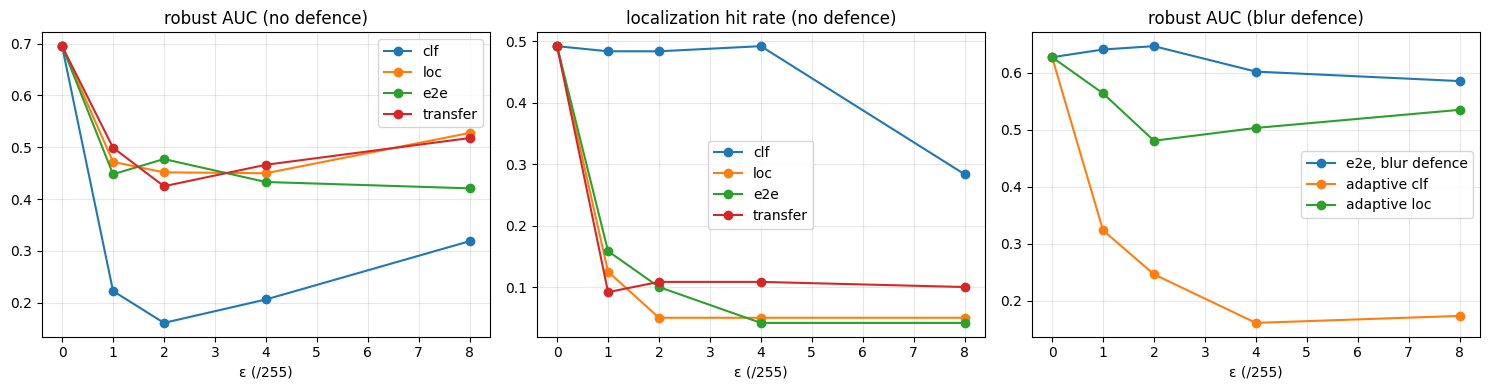

Check: MMR = 0 and ACC = share of malignant means the attacked receiver calls EVERYTHING malignant (false alarms, not missed cancers).


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for kind in ("clf", "loc", "e2e", "transfer"):
    s = A_res[(A_res.attack.isin([kind, "none"])) & (A_res.defence == "none")].sort_values("eps")
    ax[0].plot(s.eps, s.AUC, "o-", label=kind); ax[1].plot(s.eps, s.loc_hit, "o-", label=kind)
for kind, lab in (("e2e", "e2e, blur defence"), ("adaptive_clf", "adaptive clf"), ("adaptive_loc", "adaptive loc")):
    s = A_res[(A_res.attack.isin([kind, "none"])) & (A_res.defence == "blur")].sort_values("eps")
    ax[2].plot(s.eps, s.AUC, "o-", label=lab)
for a, t in zip(ax, ("robust AUC (no defence)", "localization hit rate (no defence)", "robust AUC (blur defence)")):
    a.set_title(t); a.set_xlabel("ε (/255)"); a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(cfg.path("results", "adversarial_pixel_v3.png"), dpi=130); plt.show()
print("Check: MMR = 0 and ACC = share of malignant means the attacked receiver calls EVERYTHING malignant (false alarms, not missed cancers).")

## Part B1. Tag leakage (whole test set, no pixels used)
How often is the highest-tagged block on the lesion, and how many of the 4 highest-tagged blocks are on the lesion? An eavesdropper who reads the tags learns this much about where the lesion is.

In [16]:
def leak_stats(defence, imps, gtds, seed=0):
    rng = np.random.default_rng(seed); top1, top4 = [], []
    for imp, g in zip(imps, gtds):
        t = public_tags(imp, defence, rng); f = t.ravel(); idx = np.flatnonzero(imp.ravel() >= 0)
        order = idx[np.lexsort((rng.random(len(idx)), -f[idx]))][:4]
        hitb = [bool(g[min(j // t.shape[1] * BLK + BLK // 2, g.shape[0] - 1), min(j % t.shape[1] * BLK + BLK // 2, g.shape[1] - 1)]) for j in order]
        top1.append(hitb[0]); top4.append(np.mean(hitb))
    return top1, top4

def leakage():
    te_l = te_all if not N_LEAK else te_all.iloc[:N_LEAK]; acc = {d: ([], []) for d in ("none", "decoy", "random")}
    for s in range(0, len(te_l), 40):
        sub = te_l.iloc[s:s + 40]; ii = sub.img_idx.values
        im = np.stack([to01(images[i]) for i in ii]); hh = [np.asarray(heat[i], np.float32) for i in ii]
        gts = [cv2.dilate((masks[i] > 0).astype(np.uint8), _k) > 0 for i in ii]
        imps = importance_sets(cfg, im, hh, clf)["clinical"]
        for d in acc:
            a, b = leak_stats(d, imps, gts, seed=s); acc[d][0].extend(a); acc[d][1].extend(b)
    return [dict(tag_defence=d, n=len(v[0]), top1_on_lesion=float(np.mean(v[0])), top1_se=float(np.std(v[0]) / np.sqrt(len(v[0]))),
                 top4_on_lesion=float(np.mean(v[1]))) for d, v in acc.items()]
L_res = pd.DataFrame(cached("B|leak", leakage)); L_res.to_csv(cfg.path("results", "tag_leakage_v3.csv"), index=False); display(L_res.round(3))
print("reference: a random block of the image is on the lesion far less often (lesion blocks are ~6 of ~236).")

,tag_defence,n,top1_on_lesion,top1_se,top4_on_lesion
0,none,453,0.503,0.023,0.486
1,decoy,453,0.042,0.009,0.034
2,random,453,0.494,0.023,0.443


reference: a random block of the image is on the lesion far less often (lesion blocks are ~6 of ~236).


## Part B2. Tag attacks and defences on the packet simulator
Same network model as notebook 03 (code copied from it).

In [17]:
import numpy as np
from collections import deque

PKT_PAYLOAD, PKT_HDR = 1024, 36            # one 32x32 uint8 block per packet; IPv4(20)+UDP(8)+app header(8)
PKT_BYTES = PKT_PAYLOAD + PKT_HDR

BASE = dict(loss_model="iid",   # "iid" = Bernoulli loss, "ge" = Gilbert-Elliott (bursty)
            loss=0.0,           # average packet loss probability of the last hop
            burst_len=8.0,      # mean burst length in packets (Gilbert-Elliott only)
            send_pps=1200.0,    # sender pacing rate, packets/s (about 10 Mbit/s with 1060-byte packets)
            link_pps=1200.0,    # bottleneck service rate, packets/s
            buf=30,             # bottleneck buffer in packets (FIFO, tail drop)
            owd=0.025,          # one-way propagation delay, s
            jitter=0.005,       # mean of the exponential delay noise, s
            deadline=2.0,       # a block is useful only if it is available before this time, s
            rho=0.20,           # protection budget: extra packets = rho x number of blocks
            arq_rounds=2)       # maximum number of retransmission rounds


class Path:
    """Sender pacing -> bottleneck FIFO queue (tail drop) -> lossy last hop (iid or Gilbert-Elliott) -> delay + jitter."""

    def __init__(self, sc, rng, trace=False):
        self.sc, self.rng, self.trace = sc, rng, trace
        self.q, self.last_dep, self.t_send, self.bad, self.qtrace = deque(), 0.0, 0.0, False, []
        gl, bl = float(sc["loss"]), max(float(sc["burst_len"]), 1.0)
        self.p_bg = 1.0 / bl                                          # bad -> good
        self.p_gb = self.p_bg * gl / (1 - gl) if gl < 1 else 1.0      # good -> bad  (stationary P(bad) = gl)
        self._redraw()

    def _redraw(self):
        if self.sc["loss_model"] == "ge":
            self.bad = self.rng.random() < self.sc["loss"]

    def begin(self, t0):
        """Start a new burst of packets at time t0 (e.g. a retransmission round). The channel state is decorrelated."""
        self.t_send = max(self.t_send, t0)
        self._redraw()

    def send(self):
        """Send one packet. Returns (send_time, arrival_time or inf, 'ok' | 'queue' | 'channel')."""
        sc, rng = self.sc, self.rng
        ts = self.t_send; self.t_send += 1.0 / sc["send_pps"]
        while self.q and self.q[0] <= ts:
            self.q.popleft()
        if self.trace:
            self.qtrace.append((ts, len(self.q)))
        if len(self.q) >= sc["buf"]:
            return ts, np.inf, "queue"
        dep = max(ts, self.last_dep) + 1.0 / sc["link_pps"]
        self.last_dep = dep; self.q.append(dep)
        if sc["loss_model"] == "ge":
            if self.bad:
                if rng.random() < self.p_bg: self.bad = False
            elif rng.random() < self.p_gb:
                self.bad = True
            lost = self.bad
        else:
            lost = rng.random() < sc["loss"]
        if lost:
            return ts, np.inf, "channel"
        return ts, dep + sc["owd"] + (rng.exponential(sc["jitter"]) if sc["jitter"] > 0 else 0.0), "ok"


# ------------------------------------------------------------------ protection plans
def _groups_uep(order, P, K=4):
    """Unequal error protection: the whole parity budget goes to the top-ranked blocks, rate-1/2 code (r = k)."""
    m = int(min(len(order), P)); prot = list(order[:m])
    groups = [dict(data=prot[i:i + K], r=len(prot[i:i + K])) for i in range(0, m, K)]
    return groups, list(order[m:])


def _groups_even(order, P, K=16):
    """Equal error protection: groups of K blocks, the same total parity budget spread evenly over all of them."""
    order = list(order)
    G = int(np.ceil(len(order) / K))
    if G == 0:
        return [], []
    base, extra = divmod(int(P), G)
    return [dict(data=order[i * K:(i + 1) * K], r=base + (1 if i < extra else 0)) for i in range(G)], []


def _emit(groups, plain, depth=8):
    """Packet sequence. Groups are interleaved in super-frames of `depth` groups so that a burst hits each group only once."""
    seq = []
    for s in range(0, len(groups), depth):
        sf = groups[s:s + depth]
        L = max(len(g["data"]) + g["r"] for g in sf)
        for j in range(L):
            for gi, g in enumerate(sf):
                k = len(g["data"])
                if j < k: seq.append(("d", g["data"][j], s + gi))
                elif j < k + g["r"]: seq.append(("p", -1, s + gi))
    return seq + [("d", b, -1) for b in plain]


def transmit(imp, order_mode, protect, sc, rng, trace=False):
    """Send one image. imp >= 0: block is sent (value = priority), -1: not sent.
    order_mode: 'shuffle' (random order, no knowledge) | 'priority' (highest priority first)
    protect   : 'none' | 'fec_even' | 'fec_uep' | 'arq'
    Returns dict(recv, t_avail, stats, order, P, qtrace)."""
    flat = np.asarray(imp, float).ravel(); idx = np.flatnonzero(flat >= 0); n = len(idx)
    t_avail = np.full(flat.size, np.inf)
    if n == 0:
        return dict(recv=np.zeros(imp.shape, bool), t_avail=t_avail.reshape(imp.shape), stats={}, order=idx, P=0, qtrace=[])
    order = idx[np.lexsort((rng.random(n), -flat[idx]))] if order_mode == "priority" else rng.permutation(idx)
    P = int(round(sc["rho"] * n)) if protect != "none" else 0
    if protect == "fec_uep":   groups, plain = _groups_uep(order, P)
    elif protect == "fec_even": groups, plain = _groups_even(order, P)
    else:                      groups, plain = [], list(order)
    seq = _emit(groups, plain)
    path = Path(sc, rng, trace)
    log = []                                                    # (kind, id, group, send time, arrival, why)
    garr = {}                                                   # group -> arrival times of its delivered packets

    def push(kind, ident, grp):
        ts, arr, why = path.send(); log.append((kind, ident, grp, ts, arr, why))
        if np.isfinite(arr):
            if kind in ("d", "r"): t_avail[ident] = min(t_avail[ident], arr)
            if grp >= 0: garr.setdefault(grp, []).append(arr)

    for kind, ident, grp in seq:
        push(kind, ident, grp)
    for g, mem in enumerate(groups):                            # erasure decoding (idealised MDS code, e.g. Reed-Solomon)
        k = len(mem["data"]); a = np.sort(garr.get(g, []))
        if len(a) >= k > 0:
            for b in mem["data"]:
                t_avail[b] = min(t_avail[b], a[k - 1])
    if protect == "arq":                                        # selective retransmission of the still-missing blocks
        budget = P
        for _ in range(sc["arq_rounds"]):
            miss = [b for b in order if not np.isfinite(t_avail[b])]
            if not miss or budget <= 0:
                break
            t_nack = path.last_dep + 2 * sc["owd"] + 3 * sc["jitter"]     # receiver notices the gap, NACK travels back
            if t_nack + sc["owd"] >= sc["deadline"]:
                break
            retx = miss[:budget]; path.begin(t_nack)
            for b in retx:
                push("r", b, -1)
            budget -= len(retx)

    recv_flat = t_avail <= sc["deadline"]
    kinds = np.array([r[0] for r in log]); ts_ = np.array([r[3] for r in log]); arr_ = np.array([r[4] for r in log])
    why = np.array([r[5] for r in log]); ok = np.isfinite(arr_); tr = (arr_ - ts_)[ok]
    got = t_avail[idx][recv_flat[idx]]; comp = float(got.max()) if got.size else np.nan
    stats = dict(pkts_sent=len(log), overhead=float(((kinds == "p") | (kinds == "r")).sum() / n),
                 pkt_loss=float((~ok).mean()), queue_drops=int((why == "queue").sum()), late_pkts=int((arr_[ok] > sc["deadline"]).sum()),
                 block_delivery=float(recv_flat[idx].mean()),
                 delay_ms=float(1e3 * tr.mean()) if tr.size else np.nan,
                 p95_delay_ms=float(1e3 * np.percentile(tr, 95)) if tr.size else np.nan,
                 jitter_ms=float(1e3 * np.abs(np.diff(tr)).mean()) if tr.size > 1 else np.nan,
                 completion_s=comp, goodput_KBps=float(recv_flat[idx].sum() * PKT_PAYLOAD / 1024 / comp) if comp and comp > 0 else np.nan)
    return dict(recv=recv_flat.reshape(imp.shape), t_avail=t_avail.reshape(imp.shape), stats=stats, order=order, P=P, qtrace=path.qtrace)


S = lambda **kw: {**BASE, "rho": RHO, "burst_len": BURST_LEN, **kw}      # scenario = BASE + overrides

In [18]:
IMPS = importance_sets(cfg, img01, list(H), clf)               # none / conventional / clinical for the attack subset
TX = [a >= 0 for a in IMPS["none"]]; GT = [m for m in M]
LES = [m[:t.shape[0] * BLK, :t.shape[1] * BLK].reshape(t.shape[0], BLK, t.shape[1], BLK).any((1, 3)) & t for m, t in zip(GT, TX)]
NT = min(N_TAG, N); IT = np.arange(NT)
SC_TAG = {"burst30": S(loss_model="ge", loss=.3), "congestion50": S(link_pps=.5 * BASE["send_pps"])}
STR_TAG = {"Uniform+FEC": ("none", "shuffle", "fec_even"), "Proposed+UEP-FEC": ("clinical", "priority", "fec_uep"), "Proposed+sel-ARQ": ("clinical", "priority", "arq")}

def network_stage(imp_true, strat, defence, attack_kind, k, sc, i, base_img):
    """one image: public tags -> (attack on tags) -> packet transmission -> (erase attack) -> damaged image. Returns (damaged, recv, sent)."""
    src, om, pr = STR_TAG[strat]; rt = np.random.default_rng([cfg.seed, 99, i]); rn = np.random.default_rng([cfg.seed, i])
    sent = imp_true >= 0; has_tags = om == "priority"
    enc = defence == "encrypt"
    tags = public_tags(imp_true, "none" if enc else defence, rt) if has_tags else imp_true
    kind = attack_kind if has_tags or attack_kind in ("none", "erase") else "none"
    if enc and kind in ("invert", "inject"): kind = "none"                       # authenticated tags: forgery is rejected
    used, erased = tag_attack(kind, imp_true, tags, k, rt, reads_tags=has_tags and not enc)
    res = transmit(np.where(sent, used, -1.) if has_tags else imp_true, om, pr, sc, rn)
    recv = res["recv"] & ~erased if erased is not None else res["recv"]
    return apply_loss(base_img, sent & ~recv, BLK, cfg.recon)[0], recv, sent

def tag_condition(strat, defence, attack_kind, k, scn):
    imp_src = IMPS[STR_TAG[strat][0]]; dmg, ld, bd = [], [], []
    for i in range(NT):
        d, recv, sent = network_stage(imp_src[i], strat, defence, attack_kind, k, SC_TAG[scn], i, img01[i])
        dmg.append(d); bd.append(recv[sent].mean()); ld.append(recv[LES[i]].mean() if LES[i].any() else np.nan)
    return dict(strategy=strat, tag_defence=defence, attack=attack_kind, k=k, scenario=scn, lesion_delivery=float(np.nanmean(ld)),
                block_delivery=float(np.mean(bd)), **summ(ev(np.stack(dmg)), IT))

confs = [("Uniform+FEC", "none", a, k) for a, k in (("none", 0), ("erase", K_TAG[0]), ("erase", K_TAG[1]))]
for strat in ("Proposed+UEP-FEC", "Proposed+sel-ARQ"):
    for d in ("none", "decoy", "random", "encrypt"):
        confs += [(strat, d, "none", 0)] + [(strat, d, a, k) for a in ("erase", "invert", "inject") for k in K_TAG]
B_rows = []
for scn in SC_TAG:
    for j, (strat, d, a, k) in enumerate(confs):
        B_rows.append(cached(f"B|{scn}|{strat}|{d}|{a}|{k}", lambda: tag_condition(strat, d, a, k, scn)))
    print("done scenario", scn, f"({len(confs)} conditions)")
B_res = pd.DataFrame(B_rows); B_res.to_csv(cfg.path("results", "adversarial_tags_v3.csv"), index=False)
display(B_res[B_res.scenario == "burst30"][["strategy", "tag_defence", "attack", "k", "lesion_delivery", "block_delivery", "AUC", "AUC_lo", "AUC_hi", "MMR", "loc_hit"]].round(3))

done scenario burst30 (59 conditions)
done scenario congestion50 (59 conditions)


,strategy,tag_defence,attack,k,lesion_delivery,block_delivery,AUC,AUC_lo,AUC_hi,MMR,loc_hit
0,Uniform+FEC,none,none,0,0.728,0.736,0.520,0.390,0.638,0.595,0.22
1,Uniform+FEC,none,erase,4,0.716,0.722,0.512,0.379,0.642,0.595,0.23
2,Uniform+FEC,none,erase,16,0.667,0.682,0.578,0.470,0.698,0.541,0.15
3,Proposed+UEP-FEC,none,none,0,0.854,0.747,0.692,0.565,0.798,0.459,0.30
4,Proposed+UEP-FEC,none,erase,4,0.635,0.730,0.708,0.611,0.822,0.514,0.13
5,Proposed+UEP-FEC,none,erase,16,0.311,0.679,0.620,0.506,0.720,0.595,0.06
6,Proposed+UEP-FEC,none,invert,4,0.736,0.747,0.565,0.440,0.669,0.541,0.25
7,Proposed+UEP-FEC,none,invert,16,0.736,0.747,0.565,0.440,0.669,0.541,0.25
8,Proposed+UEP-FEC,none,inject,4,0.867,0.747,0.654,0.525,0.773,0.432,0.34
9,Proposed+UEP-FEC,none,inject,16,0.859,0.747,0.568,0.438,0.707,0.568,0.30


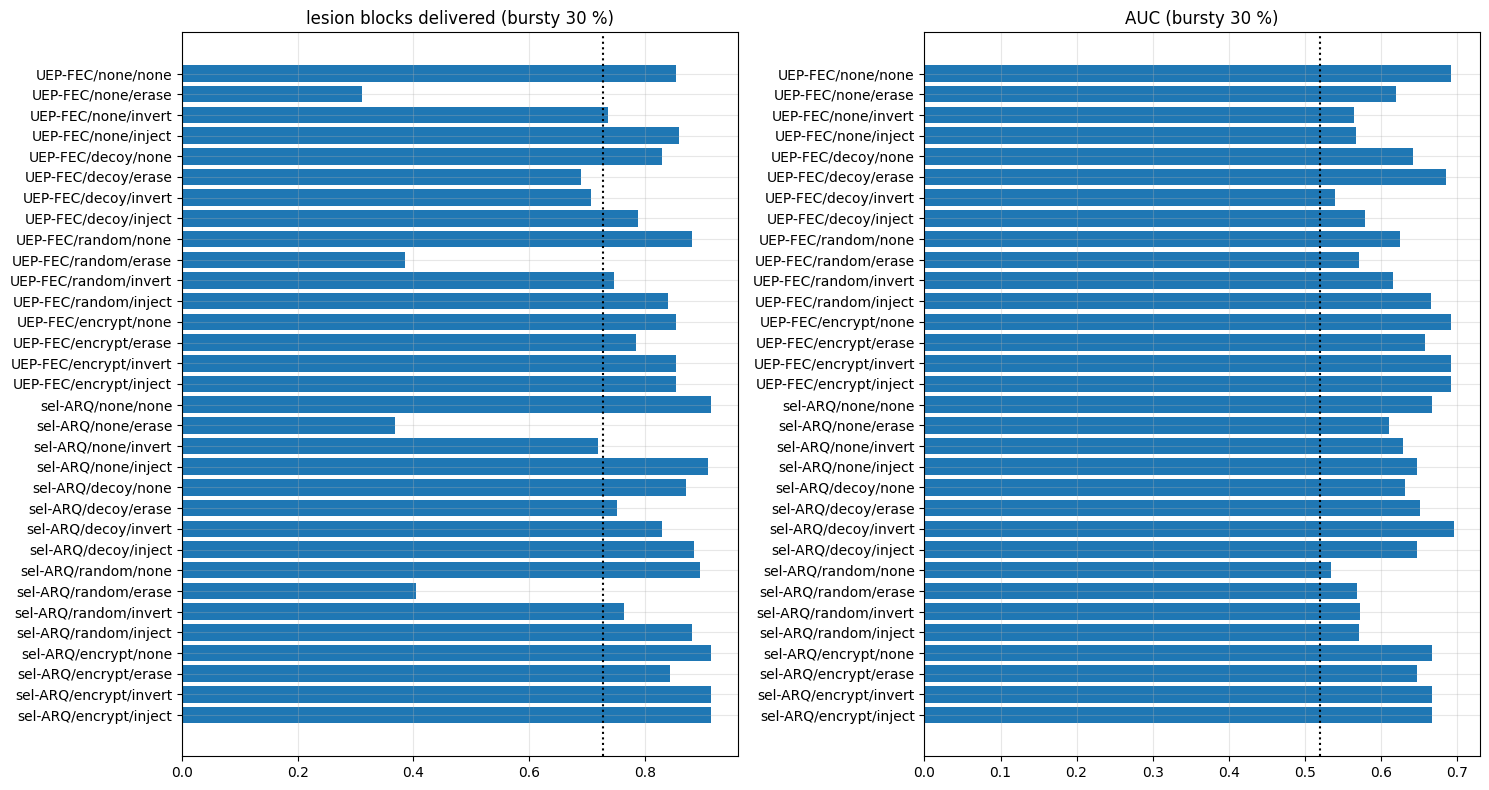

dotted line = Uniform+FEC without attack (the non-semantic baseline at the same overhead)


In [19]:
sub = B_res[(B_res.scenario == "burst30") & (B_res.k.isin([0, K_TAG[-1]])) & (B_res.strategy != "Uniform+FEC")].copy()
sub["name"] = sub.strategy.str.replace("Proposed+", "") + "/" + sub.tag_defence + "/" + sub.attack
fig, ax = plt.subplots(1, 2, figsize=(15, 8))
for a, col, t in zip(ax, ("lesion_delivery", "AUC"), ("lesion blocks delivered (bursty 30 %)", "AUC (bursty 30 %)")):
    a.barh(sub.name, sub[col]); a.set_title(t); a.grid(alpha=.3); a.invert_yaxis()
ref = B_res[(B_res.scenario == "burst30") & (B_res.strategy == "Uniform+FEC") & (B_res.attack == "none")].iloc[0]
ax[0].axvline(ref.lesion_delivery, color="k", ls=":"); ax[1].axvline(ref.AUC, color="k", ls=":")
plt.tight_layout(); plt.savefig(cfg.path("results", "adversarial_tags_v3.png"), dpi=130); plt.show()
print("dotted line = Uniform+FEC without attack (the non-semantic baseline at the same overhead)")

## Part C. Combined: pixel attack (e2e PGD) + lossy network
The attacker perturbs the image after the sender computed the priorities; the packet network then loses blocks. Priorities come from the clean image.

In [20]:
NC = min(N_PIXEL, N); IC = np.arange(NC)
SC_C = {"clean link": S(), "bursty 30%": S(loss_model="ge", loss=.3), "congestion 50%": S(link_pps=.5 * BASE["send_pps"])}
ADV = {0: img01[:NC]}
for e in (4, 8): ADV[e] = np.load(adv_path(e)).astype(np.float32)[:NC] / 255

def comb_condition(e, scn, strat):
    src, om, pr = STR_TAG[strat]; dmg, ld = [], []
    for i in range(NC):
        imp = IMPS[src][i]; res = transmit(imp, om, pr, SC_C[scn], np.random.default_rng([cfg.seed, i])); sent = imp >= 0
        dmg.append(apply_loss(ADV[e][i], sent & ~res["recv"], BLK, cfg.recon)[0]); ld.append(res["recv"][LES[i]].mean() if LES[i].any() else np.nan)
    return dict(eps=e, scenario=scn, strategy=strat, lesion_delivery=float(np.nanmean(ld)), **summ(ev(np.stack(dmg)), IC))
C_res = pd.DataFrame([cached(f"C|{e}|{scn}|{st}", lambda: comb_condition(e, scn, st)) for e in (0, 4, 8) for scn in SC_C for st in STR_TAG])
C_res.to_csv(cfg.path("results", "adversarial_combined_v3.csv"), index=False)
display(C_res[["eps", "scenario", "strategy", "lesion_delivery", "AUC", "AUC_lo", "AUC_hi", "ACC", "ASR", "MMR", "loc_hit"]].round(3))

,eps,scenario,strategy,lesion_delivery,AUC,AUC_lo,AUC_hi,ACC,ASR,MMR,loc_hit
0,0,clean link,Uniform+FEC,1.000,0.695,0.606,0.797,0.575,0.000,0.340,0.492
1,0,clean link,Proposed+UEP-FEC,1.000,0.695,0.606,0.797,0.575,0.000,0.340,0.492
2,0,clean link,Proposed+sel-ARQ,1.000,0.695,0.606,0.797,0.575,0.000,0.340,0.492
3,0,bursty 30%,Uniform+FEC,0.721,0.520,0.412,0.630,0.508,0.377,0.553,0.200
4,0,bursty 30%,Proposed+UEP-FEC,0.856,0.708,0.621,0.807,0.650,0.174,0.468,0.308
5,0,bursty 30%,Proposed+sel-ARQ,0.916,0.660,0.564,0.768,0.633,0.174,0.404,0.367
6,0,congestion 50%,Uniform+FEC,0.681,0.581,0.464,0.698,0.592,0.333,0.638,0.125
7,0,congestion 50%,Proposed+UEP-FEC,0.886,0.670,0.580,0.759,0.567,0.261,0.340,0.342
8,0,congestion 50%,Proposed+sel-ARQ,0.979,0.676,0.582,0.773,0.608,0.116,0.362,0.383
9,4,clean link,Uniform+FEC,1.000,0.433,0.322,0.529,0.392,0.551,0.000,0.042


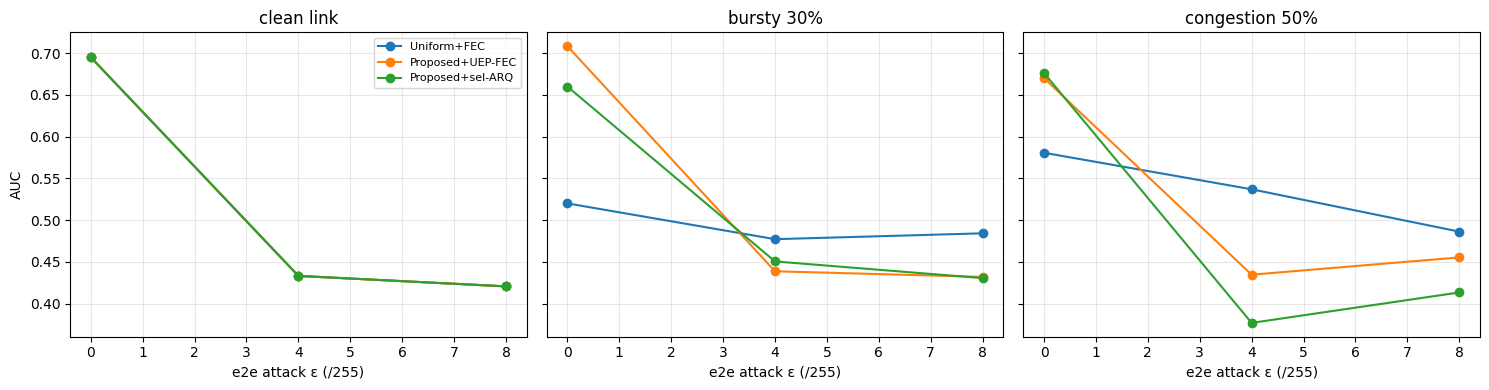

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, scn in zip(ax, SC_C):
    for st in STR_TAG:
        s = C_res[(C_res.scenario == scn) & (C_res.strategy == st)].sort_values("eps"); a.plot(s.eps, s.AUC, "o-", label=st)
    a.set_title(scn); a.set_xlabel("e2e attack ε (/255)"); a.grid(alpha=.3)
ax[0].set_ylabel("AUC"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(cfg.path("results", "adversarial_combined_v3.png"), dpi=130); plt.show()

## Part D (optional). Adversarial fine-tuning of the classifier
Set `DO_AT = True` to fine-tune a copy of the classifier on PGD-perturbed training crops (ε = 4/255, lesion-centred crops) and re-measure the white-box `clf` attack.
Compact version (a few hundred steps); it can lower clean AUC, so compare both. It attacks the classifier only, not the localizer.

In [22]:
DO_AT = False
if DO_AT:
    import copy, torch.nn.functional as Fn
    from src.attack_v2 import crop_input
    from src.train_v2 import image_centres
    tr = images_df[(images_df.split == "train") & (~images_df.mixed)]; cen = image_centres(abn_df, len(images_df))
    clf_at = copy.deepcopy(clf).train()
    for p in clf_at.parameters(): p.requires_grad_(False)
    ps = [p for n, p in clf_at.named_parameters() if n.startswith(("bb.layer3", "bb.layer4", "D", "w"))]
    for p in ps: p.requires_grad_(True)
    opt = torch.optim.Adam(ps, 1e-5); rng = np.random.default_rng(0); alpha = float((tr.label == 0).sum() / (tr.label == 1).sum())
    for step in range(300):
        b = tr.sample(8, random_state=int(rng.integers(1e9)))
        x = T(np.stack([to01(images[i]) for i in b.img_idx])); hh = T(np.stack([np.asarray(heat[i], np.float32) for i in b.img_idx]))
        yy = torch.tensor(b.label.values, dtype=torch.float32, device=DEVICE); cc = cen[b.img_idx.values]
        clf_at.eval(); xa = attack("clf", x, yy.cpu().numpy(), hh, cc, None, localizers, clf_at, cfg, 4 / 255, 3); clf_at.train()
        w = torch.where(yy > 0, torch.full_like(yy, alpha), torch.ones_like(yy))
        loss = sum(Fn.binary_cross_entropy_with_logits(clf_at(crop_input(z, hh, cc, cfg))[2], yy, weight=w) for z in (x, xa)) / 2
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 50 == 0: print(step, float(loss))
    clf_at.eval(); [p.requires_grad_(False) for p in clf_at.parameters()]
    rec_at = ReceiverV2(cfg, localizers, clf_at, sigma=lm["sigma"]); D_rows = []
    for name, rc, cl in (("original", receiver, clf), ("adv-trained", ReceiverV2(cfg, localizers, clf_at, sigma=lm["sigma"]), clf_at)):
        for e in (0, 4, 8):
            adv = img01[:N_PIXEL] if e == 0 else np.concatenate([attack("clf", T(img01[s:s + BS]), y[s:s + BS], T(H_t[s:s + BS]), c0[s:s + BS], None, localizers, cl, cfg, e / 255, STEPS)[:, 0].cpu().numpy() for s in range(0, N_PIXEL, BS)])
            r = diagnose_all(rc, adv); D_rows.append(dict(classifier=name, eps=e, AUC=auc_safe(y[:N_PIXEL], r["p"])))
    D_res = pd.DataFrame(D_rows); D_res.to_csv(cfg.path("results", "adversarial_training_v3.csv"), index=False); display(D_res.round(3))

In [23]:
from src.attack_v2 import crop_input
rows = []
def probs_from_crop(adv, heat_t, centres):
    out = []
    with torch.no_grad():
        for s in range(0, len(adv), BS):
            x = T(adv[s:s + BS]); h = T(heat_t[s:s + BS])
            out.append(torch.sigmoid(clf(crop_input(x, h, centres[s:s + BS], cfg))[2]).cpu().numpy())
    return np.concatenate(out)

pc = probs_from_crop(img01[:NC], H_t[:NC], c0[:NC])                              # clean reference
rows.append(dict(case="clean", eps=0, mean_p_malignant=pc[y[:NC] == 1].mean(), mean_p_benign=pc[y[:NC] == 0].mean(), share_called_malignant=(pc >= THR).mean()))
clean_conf = diagnose_all(receiver, img01[:NC])["loc_conf"].mean()
for e in (4, 8):
    adv = np.load(adv_path(e)).astype(np.float32)[:NC] / 255
    r = diagnose_all(receiver, adv)                                              # normal pipeline on the attacked image
    p_pix = probs_from_crop(adv, H_t[:NC], c0[:NC])                              # attacked pixels, but CLEAN heat-map and CLEAN crop centre
    for name, p in (("pipeline (re-localized)", r["p"]), ("attacked pixels, clean crop + clean map", p_pix)):
        rows.append(dict(case=name, eps=e, mean_p_malignant=p[y[:NC] == 1].mean(), mean_p_benign=p[y[:NC] == 0].mean(), share_called_malignant=(p >= THR).mean()))
    print(f"eps {e}: mean localization confidence clean {clean_conf:.3f} -> attacked {r['loc_conf'].mean():.3f}")
display(pd.DataFrame(rows).round(3))

eps 4: mean localization confidence clean 0.767 -> attacked 1.000
eps 8: mean localization confidence clean 0.767 -> attacked 1.000


,case,eps,mean_p_malignant,mean_p_benign,share_called_malignant
0,clean,0,0.539,0.455,0.525
1,pipeline (re-localized),4,0.695,0.707,1.000
2,"attacked pixels, clean crop + clean map",4,0.518,0.457,0.558
3,pipeline (re-localized),8,0.648,0.671,1.000
4,"attacked pixels, clean crop + clean map",8,0.483,0.459,0.575


In [24]:
DO_AT = True
if DO_AT:
    import copy, torch.nn.functional as Fn
    from src.attack_v2 import crop_input
    from src.train_v2 import image_centres
    freeze_bn = lambda m: m.eval() if isinstance(m, torch.nn.BatchNorm2d) else None     # keep the frozen ResNet's BN statistics fixed
    tr = images_df[(images_df.split == "train") & (~images_df.mixed)]; cen = image_centres(abn_df, len(images_df))
    clf_at = copy.deepcopy(clf).train(); clf_at.bb.apply(freeze_bn)
    for p in clf_at.parameters(): p.requires_grad_(False)
    ps = [p for n, p in clf_at.named_parameters() if n.startswith(("bb.layer3", "bb.layer4", "D", "w"))]
    for p in ps: p.requires_grad_(True)
    opt = torch.optim.Adam(ps, 1e-5); rng = np.random.default_rng(0); alpha = float((tr.label == 0).sum() / (tr.label == 1).sum())
    for step in range(300):
        b = tr.sample(8, random_state=int(rng.integers(1e9)))
        x = T(np.stack([to01(images[i]) for i in b.img_idx])); hh = T(np.stack([np.asarray(heat[i], np.float32) for i in b.img_idx]))
        yy = torch.tensor(b.label.values, dtype=torch.float32, device=DEVICE); cc = cen[b.img_idx.values]
        clf_at.eval(); xa = attack("clf", x, yy.cpu().numpy(), hh, cc, None, localizers, clf_at, cfg, 4 / 255, 3); clf_at.train(); clf_at.bb.apply(freeze_bn)
        w = torch.where(yy > 0, torch.full_like(yy, alpha), torch.ones_like(yy))
        loss = sum(Fn.binary_cross_entropy_with_logits(clf_at(crop_input(z, hh, cc, cfg))[2], yy, weight=w) for z in (x, xa)) / 2
        opt.zero_grad(); loss.backward(); opt.step()
        if step % 50 == 0: print(step, float(loss))
    clf_at.eval(); [p.requires_grad_(False) for p in clf_at.parameters()]
    D_rows = []
    for name, rc, cl in (("original", receiver, clf), ("adv-trained", ReceiverV2(cfg, localizers, clf_at, sigma=lm["sigma"]), clf_at)):
        for e in (0, 4, 8):
            adv = img01[:N_PIXEL] if e == 0 else np.concatenate([attack("clf", T(img01[s:s + BS]), y[s:s + BS], T(H_t[s:s + BS]), c0[s:s + BS], None, localizers, cl, cfg, e / 255, STEPS)[:, 0].cpu().numpy() for s in range(0, N_PIXEL, BS)])
            r = diagnose_all(rc, adv); D_rows.append(dict(classifier=name, eps=e, AUC=auc_safe(y[:N_PIXEL], r["p"])))
    D_res = pd.DataFrame(D_rows); D_res.to_csv(cfg.path("results", "adversarial_training_v3.csv"), index=False); display(D_res.round(3))

/tmp/ipykernel_432/1145755256.py:21: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:820.)
  if step % 50 == 0: print(step, float(loss))


0 1.022963285446167
50 0.9687952995300293
100 0.9932729601860046
150 0.8974338173866272
200 0.8958936929702759
250 0.8870953321456909


,classifier,eps,AUC
0,original,0,0.695
1,original,4,0.208
2,original,8,0.331
3,adv-trained,0,0.692
4,adv-trained,4,0.380
5,adv-trained,8,0.417


In [25]:
n = NC
conf_clean = diagnose_all(receiver, img01[:n])["loc_conf"]
rows = []
for e in (4, 8):
    adv = np.load(adv_path(e)).astype(np.float32)[:n] / 255
    conf_adv = diagnose_all(receiver, adv)["loc_conf"]
    labels = np.r_[np.zeros(n), np.ones(n)]; scores = np.r_[conf_clean, conf_adv]
    row = dict(eps=e, detector_AUC=auc_safe(labels, scores))
    for t in (0.9, 0.95, 0.99, 0.999):
        row[f"clean_flagged@{t}"] = float((conf_clean >= t).mean())
        row[f"attacked_flagged@{t}"] = float((conf_adv >= t).mean())
    rows.append(row)
display(pd.DataFrame(rows).round(3))
print("clean confidence: min %.3f median %.3f max %.3f" % (conf_clean.min(), np.median(conf_clean), conf_clean.max()))

,eps,detector_AUC,clean_flagged@0.9,attacked_flagged@0.9,clean_flagged@0.95,attacked_flagged@0.95,clean_flagged@0.99,attacked_flagged@0.99,clean_flagged@0.999,attacked_flagged@0.999
0,4,1.0,0.475,1.0,0.383,1.0,0.142,1.0,0.025,1.0
1,8,1.0,0.475,1.0,0.383,1.0,0.142,1.0,0.025,1.0


clean confidence: min 0.158 median 0.886 max 1.000


In [26]:
def conf_of(imgs): return diagnose_all(receiver, imgs)["loc_conf"]
T_LIST = (0.99, 0.999)
def flag_row(case, conf):
    return dict(case=case, mean_conf=float(np.mean(conf)), **{f"flagged@{t}": float((conf >= t).mean()) for t in T_LIST})

def through_network(base, strat, scn):
    src, om, pr = STR_TAG[strat]; dmg = []
    for i in range(NC):
        imp = IMPS[src][i]; res = transmit(imp, om, pr, SC_C[scn], np.random.default_rng([cfg.seed, i])); sent = imp >= 0
        dmg.append(apply_loss(base[i], sent & ~res["recv"], BLK, cfg.recon)[0])
    return np.stack(dmg)

rows = [flag_row("clean, no loss", conf_of(img01[:NC]))]
for scn in ("bursty 30%", "congestion 50%"):                       # 1) false alarms: clean images that went through the lossy network
    for strat in STR_TAG:
        rows.append(flag_row(f"CLEAN through {scn}, {strat}", conf_of(through_network(img01[:NC], strat, scn))))
for e in (4, 8):                                                   # 2) attacked images that then went through the lossy network
    for scn in ("bursty 30%", "congestion 50%"):
        for strat in STR_TAG:
            rows.append(flag_row(f"ATTACK e2e {e}/255 through {scn}, {strat}", conf_of(through_network(ADV[e], strat, scn))))
for e in (1, 2):                                                   # 3) weaker attacks (crafted again, about 3 min each)
    rows.append(flag_row(f"ATTACK e2e {e}/255, clean link", conf_of(craft("e2e", e))))
D2 = pd.DataFrame(rows); D2.to_csv(cfg.path("results", "detector_check_v3.csv"), index=False); display(D2.round(3))

,case,mean_conf,flagged@0.99,flagged@0.999
0,"clean, no loss",0.767,0.142,0.025
1,"CLEAN through bursty 30%, Uniform+FEC",0.791,0.025,0.000
2,"CLEAN through bursty 30%, Proposed+UEP-FEC",0.851,0.092,0.017
3,"CLEAN through bursty 30%, Proposed+sel-ARQ",0.860,0.100,0.000
4,"CLEAN through congestion 50%, Uniform+FEC",0.778,0.017,0.000
5,"CLEAN through congestion 50%, Proposed+UEP-FEC",0.816,0.083,0.000
6,"CLEAN through congestion 50%, Proposed+sel-ARQ",0.843,0.133,0.025
7,"ATTACK e2e 4/255 through bursty 30%, Uniform+FEC",1.000,1.000,1.000
8,"ATTACK e2e 4/255 through bursty 30%, Proposed+...",1.000,1.000,1.000
9,"ATTACK e2e 4/255 through bursty 30%, Proposed+...",1.000,1.000,1.000
